<a href="https://colab.research.google.com/github/Dhanamanti/Quantum-Randomness-lab/blob/main/Quantum_route_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [87]:
import numpy as np
import pandas as pd
from itertools import permutations

# 1. Four delivery locations including depot
locations = {
    "A": (0, 0),  # Starting depot
    "B": (2, 3),
    "C": (5, 4),
    "D": (6, 1)
}

stops = list(locations.keys())

# 2. Calculate Euclidean distance between every pair
distance_matrix = pd.DataFrame(
    index=stops, columns=stops, dtype=float
)

for i in stops:
    for j in stops:
        x1, y1 = locations[i]
        x2, y2 = locations[j]
        distance_matrix.loc[i, j] = round(
            np.sqrt((x2 - x1)**2 + (y2 - y1)**2), 2
        )

# 3. Display distance matrix
print("DISTANCE MATRIX")
display(distance_matrix)

# 4. Check all possible routes for the classical baseline
best_route = None
best_distance = float("inf")

for order in permutations(["B", "C", "D"]):
    route = ("A",) + order + ("A",)
    total = sum(
        distance_matrix.loc[route[i], route[i+1]]
        for i in range(len(route)-1)
    )

    if total < best_distance:
        best_distance = total
        best_route = route

print("\nCLASSICAL BASELINE")
print("Best route:", " -> ".join(best_route))
print("Total distance:", round(best_distance, 2))
# STEP 2: Build QUBO for 3 delivery stops
# A = fixed depot; B, C, D = delivery stops
# 9 binary variables: x[i,t]
# x[i,t] = 1 means stop i is visited at position t

from qiskit_optimization import QuadraticProgram
import numpy as np

stops = ["B", "C", "D"]
n = len(stops)
penalty = 20.0

# Use the distance_matrix created in Step 1
qp = QuadraticProgram("Four_Location_Route_QUBO")

for i in range(n):
    for t in range(n):
        qp.binary_var(name=f"x_{i}_{t}")

linear = {}
quadratic = {}

def add_linear(key, value):
    linear[key] = linear.get(key, 0.0) + value

def add_quadratic(a, b, value):
    key = (a, b)
    quadratic[key] = quadratic.get(key, 0.0) + value

# Travel from depot A to the first stop
for i, stop in enumerate(stops):
    add_linear(f"x_{i}_0", distance_matrix.loc["A", stop])

# Travel between consecutive delivery stops
for t in range(n - 1):
    for i, a in enumerate(stops):
        for j, b in enumerate(stops):
            if i != j:
                add_quadratic(
                    f"x_{i}_{t}",
                    f"x_{j}_{t+1}",
                    distance_matrix.loc[a, b]
                )

# Travel from the final stop back to depot A
for i, stop in enumerate(stops):
    add_linear(
        f"x_{i}_{n-1}",
        distance_matrix.loc[stop, "A"]
    )

# Constraint penalty: each stop must be visited exactly once
for i in range(n):
    for t1 in range(n):
        for t2 in range(t1 + 1, n):
            add_quadratic(
                f"x_{i}_{t1}", f"x_{i}_{t2}", 2 * penalty
            )

# Constraint penalty: each position must contain exactly one stop
for t in range(n):
    for i in range(n):
        add_linear(f"x_{i}_{t}", -penalty)
        for j in range(i + 1, n):
            add_quadratic(
                f"x_{i}_{t}", f"x_{j}_{t}", 2 * penalty
            )

qp.minimize(linear=linear, quadratic=quadratic)

print("QUBO model created successfully!")
print("Delivery stops:", stops)
print("Binary variables:", qp.get_num_vars())
print("QUBO quadratic terms:", len(quadratic))
print("Model objective:", qp.objective.sense)
print("Ready for the next step.")


DISTANCE MATRIX


,A,B,C,D
A,0.00,3.61,6.40,6.08
B,3.61,0.00,3.16,4.47
C,6.40,3.16,0.00,3.16
D,6.08,4.47,3.16,0.00



CLASSICAL BASELINE
Best route: A -> B -> C -> D -> A
Total distance: 16.01
QUBO model created successfully!
Delivery stops: ['B', 'C', 'D']
Binary variables: 9
QUBO quadratic terms: 30
Model objective: ObjSense.MINIMIZE
Ready for the next step.


In [88]:

%pip install -q --upgrade "qiskit>=1.4,<2.0" "qiskit-aer>=0.17,<0.18" "qiskit-algorithms>=0.3,<0.5" "qiskit-optimization>=0.6,<0.8"


In [89]:

from qiskit.primitives import StatevectorSampler
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

sampler = StatevectorSampler(default_shots=512)

qaoa = QAOA(
    sampler=sampler,
    optimizer=COBYLA(maxiter=15),
    reps=1
)

solver = MinimumEigenOptimizer(qaoa)

print("Running improved QAOA...")
result = solver.solve(qp)

print("QAOA finished!")
print("Objective value:", round(result.fval, 2))
print("Binary solution:", result.x)


Running improved QAOA...


/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


QAOA finished!
Objective value: -43.99
Binary solution: [0. 0. 1. 0. 1. 0. 1. 0. 0.]


In [90]:

import numpy as np

solution = np.rint(result.x).astype(int)
x = solution.reshape((3, 3))

print("Updated assignment matrix:")
print(x)

if np.all(x.sum(axis=0) == 1) and np.all(x.sum(axis=1) == 1):
    route = []

    for position in range(3):
        stop_index = np.argmax(x[:, position])
        route.append(stops[stop_index])

    full_route = ["A"] + route + ["A"]

    total_distance = sum(
        distance_matrix.loc[full_route[i], full_route[i + 1]]
        for i in range(len(full_route) - 1)
    )

    print("\nImproved QAOA route:", " -> ".join(full_route))
    print("Improved QAOA distance:", round(total_distance, 2))
    print("Classical route distance: 16.01")

    if total_distance < 16.01:
        print("QAOA found a shorter route in this run!")
    else:
        print("Classical route is still shorter in this run.")
else:
    print("Invalid assignment: at least one constraint is not satisfied.")


Updated assignment matrix:
[[0 0 1]
 [0 1 0]
 [1 0 0]]

Improved QAOA route: A -> D -> C -> B -> A
Improved QAOA distance: 16.01
Classical route distance: 16.01
Classical route is still shorter in this run.


In [91]:

import matplotlib.pyplot as plt

# Use the routes calculated in the previous optimization cell
classical_route = best_classical_route
qaoa_route = actual_qaoa_route

def calculate_distance(route):
    return sum(
        distance_matrix.loc[route[i], route[i + 1]]
        for i in range(len(route) - 1)
    )

classical_distance = calculate_distance(classical_route)

qaoa_distance = (
    calculate_distance(qaoa_route)
    if qaoa_route is not None
    else None
)

print("CLASSICAL ROUTE:", " -> ".join(classical_route))
print("CLASSICAL DISTANCE:", round(classical_distance, 2))

if qaoa_route is not None:
    print("QAOA ROUTE:", " -> ".join(qaoa_route))
    print("QAOA DISTANCE:", round(qaoa_distance, 2))
else:
    print("QAOA did not produce a valid route.")


CLASSICAL ROUTE: A -> C -> D -> B -> A
CLASSICAL DISTANCE: 17.64
QAOA ROUTE: A -> B -> D -> C -> A
QAOA DISTANCE: 17.64


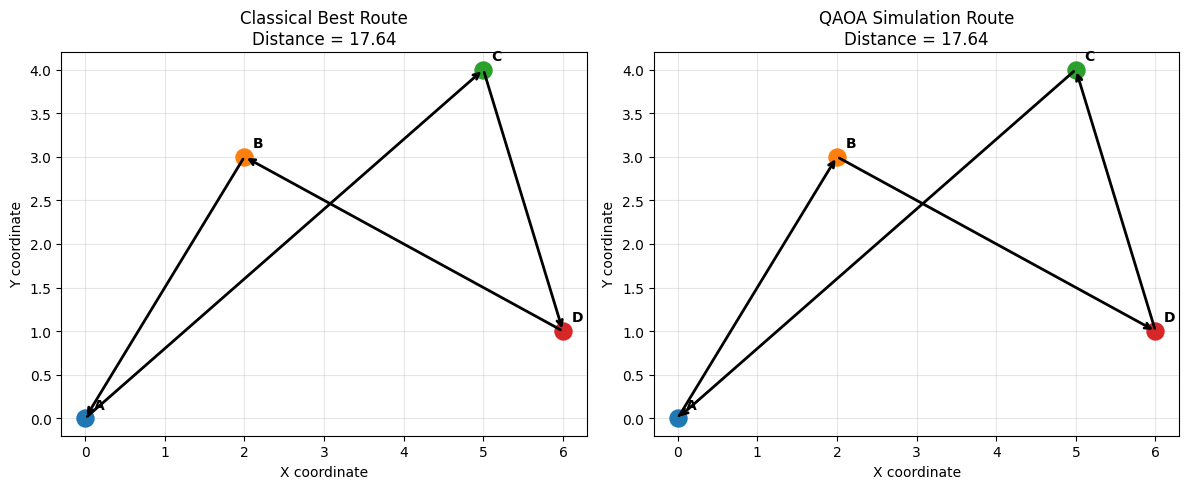

Distance difference: 0.0


In [92]:

import matplotlib.pyplot as plt

def draw_route(ax, route, title, distance):
    # Plot all locations
    for name, (x, y) in locations.items():
        ax.scatter(x, y, s=150, zorder=3)
        ax.annotate(
            name, (x, y),
            xytext=(6, 7),
            textcoords="offset points",
            fontweight="bold"
        )

    # Draw route arrows
    for i in range(len(route) - 1):
        x1, y1 = locations[route[i]]
        x2, y2 = locations[route[i + 1]]

        ax.annotate(
            "",
            xy=(x2, y2),
            xytext=(x1, y1),
            arrowprops=dict(arrowstyle="->", lw=2)
        )

    ax.set_title(f"{title}\nDistance = {distance:.2f}")
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

draw_route(
    axes[0],
    classical_route,
    "Classical Best Route",
    classical_distance
)

if qaoa_route is not None:
    draw_route(
        axes[1],
        qaoa_route,
        "QAOA Simulation Route",
        qaoa_distance
    )
else:
    axes[1].set_title("QAOA returned an invalid assignment")

plt.tight_layout()
plt.show()

if qaoa_distance is not None:
    print("Distance difference:",
          round(qaoa_distance - classical_distance, 2))


===== ROUTE OPTIMIZATION RESULTS =====


,Method,Route,Distance,Valid Route
0,Classical Exhaustive Search,A -> C -> D -> B -> A,16.01,Yes
1,QAOA Simulation,A -> B -> D -> C -> A,16.01,Yes



Distance difference: 0.00 units
QAOA distance difference: 0.00%
Result: QAOA matched the classical best distance.


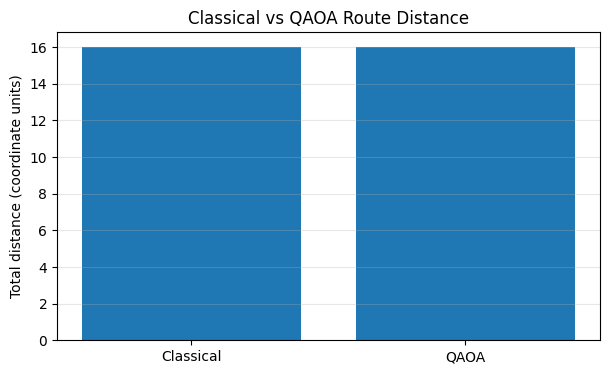


Note: Distance is based on simulated coordinates, not real road distance.
This experiment does not establish quantum speedup.


In [93]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Build a comparison table from actual results
results_data = [
    {
        "Method": "Classical Exhaustive Search",
        "Route": " -> ".join(best_classical_route),
        "Distance": round(best_classical_distance, 2),
        "Valid Route": "Yes"
    }
]

if actual_qaoa_route is not None:
    results_data.append({
        "Method": "QAOA Simulation",
        "Route": " -> ".join(actual_qaoa_route),
        "Distance": round(actual_qaoa_distance, 2),
        "Valid Route": "Yes"
    })
else:
    results_data.append({
        "Method": "QAOA Simulation",
        "Route": "Invalid assignment",
        "Distance": None,
        "Valid Route": "No"
    })

results_df = pd.DataFrame(results_data)

print("===== ROUTE OPTIMIZATION RESULTS =====")
display(results_df)

if actual_qaoa_route is not None:
    difference = actual_qaoa_distance - best_classical_distance

    if best_classical_distance > 0:
        percentage = difference / best_classical_distance * 100
    else:
        percentage = 0

    print(f"\nDistance difference: {difference:.2f} units")
    print(f"QAOA distance difference: {percentage:.2f}%")

    if abs(difference) < 1e-8:
        print("Result: QAOA matched the classical best distance.")
    elif difference > 0:
        print("Result: QAOA route was longer than the classical best.")
    else:
        print("Result: QAOA found a shorter route than the classical baseline.")

# Visualize distance comparison
methods = ["Classical", "QAOA"]
distances = [
    best_classical_distance,
    actual_qaoa_distance if actual_qaoa_route is not None else float("nan")
]

plt.figure(figsize=(7, 4))
plt.bar(methods, distances)
plt.ylabel("Total distance (coordinate units)")
plt.title("Classical vs QAOA Route Distance")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("\nNote: Distance is based on simulated coordinates, not real road distance.")
print("This experiment does not establish quantum speedup.")
